## Method 1: 1D AutoEncoder
1. Finding segments containing none zero values of a fhr signal, and keeping its pair uc signal for those times
2. Zeroing segments of those clean segments, using the mean and std of the 25% and 75% quantiles of the medians
    - Eliminating small and easy to solve zeroed segments
    - Elimination big and unsolvable zeroed segments
3. Training the autoencoder using as ground truth the original signal before segment corruption

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import numpy as np
import glob
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import pandas as pd
import random
import itertools
import os
from datetime import datetime
import json
import torch.backends.cudnn as cudnn

from helpers.dataset import InpaintingDataset
from models.definitions import ContextualUNet1D

In [ ]:
# Loss Function with two component
# reconstruction loss and gradient penalty

class InpaintingLoss(nn.Module):
    def __init__(self, alpha=0.1):
        super().__init__()
        self.alpha = alpha
        self.l1 = nn.L1Loss()
    
    def forward(self, pred, target):
        # Reconstruction loss
        recon_loss = self.l1(pred, target)
        
        # Gradient penalty for smoothness
        grad_pred = torch.diff(pred, dim=-1)
        grad_target = torch.diff(target, dim=-1)
        grad_loss = self.l1(grad_pred, grad_target)
        
        return recon_loss + self.alpha * grad_loss

In [ ]:
# Data Loading and Preparation

# Hyperparameters for data preparation

SEGMENT_LENGTH = 2048  # Must be divisible by 4 for this U-Net
DATABASE_PATH = "data/all_data/*.dat"

# Load the raw data from files
all_data = {}
fhr_gain, fhr_baseline, fs = 100.0, 0.0, 4.0
for dat_file in glob.glob(DATABASE_PATH):
    rec_id = int(dat_file.split("/")[-1].split(".")[0])
    raw_data = np.fromfile(dat_file, dtype=np.int16)
    fhr = (raw_data[0::2] - fhr_baseline) / fhr_gain
    uc = raw_data[1::2]
    all_data[rec_id] = {"fhr": fhr, "uc": uc}


counts = {}
# Extract clean segments (regions with no zeros)
print("Extracting clean segments from all recordings...")
clean_segments = []
for rec_id, signals in all_data.items():
    counts[rec_id] = 0
    fhr, uc = signals["fhr"], signals["uc"]
    num_samples = len(fhr)
    for start_idx in range(0, num_samples - SEGMENT_LENGTH, SEGMENT_LENGTH):
        end_idx = start_idx + SEGMENT_LENGTH
        fhr_segment = fhr[start_idx:end_idx]
        
        # Check if the segment contains any pre-existing zeros
        if np.count_nonzero(fhr_segment) == SEGMENT_LENGTH:
            counts[rec_id] += 1
            uc_segment = uc[start_idx:end_idx]
            # Stack FHR and UC to form a (2, length) segment
            combined_segment = np.stack([fhr_segment, uc_segment], axis=0)
            clean_segments.append(combined_segment)

print(f"Found {len(clean_segments)} clean segments of length {SEGMENT_LENGTH}.")

Extracting clean segments from all recordings...
Found 829 clean segments of length 2048.


(array([205., 101.,  63.,  44.,  37.,  30.,  16.,   6.,   2.,   2.]),
 array([0. , 0.9, 1.8, 2.7, 3.6, 4.5, 5.4, 6.3, 7.2, 8.1, 9. ]),
 <BarContainer object of 10 artists>)

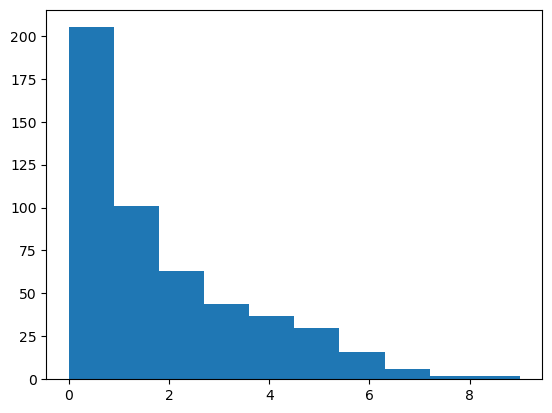

In [4]:
count_per_signal = []
for val in counts.values():
    count_per_signal.append(val)

plt.hist(count_per_signal)

In [5]:
# 60% of the data were used for clean segments

count_per_signal = pd.DataFrame(count_per_signal)
count_per_signal.value_counts(normalize=True)

0
0    0.405138
1    0.199605
2    0.124506
3    0.086957
4    0.073123
5    0.059289
6    0.031621
7    0.011858
8    0.003953
9    0.003953
Name: proportion, dtype: float64

In [ ]:
# Training Setup

# Hyperparameters for training
BATCH_SIZE = 32
EPOCHS = 1
LEARNING_RATE = 1e-4
VALIDATION_SPLIT = 0.2

# Split data into training and validation sets
train_segments, val_segments = train_test_split(
    clean_segments, test_size=VALIDATION_SPLIT, random_state=42
)

# extracted from notebook #2
mean_mask_percentage=0.004330473500925825
std_mask_percentage=0.0006158383567016473

# min and max percentage of total zeroed section of the signal
min_clip=0.05
max_clip=0.20

# Create Datasets and DataLoaders
train_dataset = InpaintingDataset(
    train_segments,
    mean_mask_percentage=mean_mask_percentage, # 2% per individual mask  
    std_mask_percentage=std_mask_percentage,   # 0.5% std
    min_clip=min_clip,                         # Total masked: 5% minimum
    max_clip=max_clip                          # Total masked: 20% maximum
)

# Share normalization statistics with validation dataset
val_dataset = InpaintingDataset(
    val_segments,
    mean_mask_percentage=mean_mask_percentage,
    std_mask_percentage=std_mask_percentage,
    min_clip=min_clip,
    max_clip=max_clip,
    fhr_mean=train_dataset.fhr_mean,
    fhr_std=train_dataset.fhr_std,
    uc_mean=train_dataset.uc_mean,
    uc_std=train_dataset.uc_std
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Training on {len(train_segments)} segments, validating on {len(val_segments)} segments.")
print(f"Normalization stats - FHR: μ={train_dataset.fhr_mean:.2f}, σ={train_dataset.fhr_std:.2f}")
print(f"Normalization stats - UC: μ={train_dataset.uc_mean:.2f}, σ={train_dataset.uc_std:.2f}")

# Setup device, model, optimizer, and loss function
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = ContextualUNet1D(in_channels=2, out_channels=1, kernel_size=3, base_channels=16, depth=1, use_intermediate_skips=True).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = InpaintingLoss(alpha=0.1).to(device)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5
)

Training on 663 segments, validating on 166 segments.
Normalization stats - FHR: μ=137.47, σ=17.29
Normalization stats - UC: μ=2195.35, σ=2203.97
Using device: cuda


In [7]:
# To solve cuda error 

cudnn.benchmark = False 
cudnn.deterministic = True 

torch.backends.cudnn.enabled = False 

os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

EPOCHS = 100
EVAL_RUNS = 100  # Number of evaluation runs with different masks

# Create output directory
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_dir = f"results/autoencoder/grid_search"
os.makedirs(output_dir, exist_ok=True)
print(f"Results will be saved to: {output_dir}\n")

# Grid search parameters
grid_params = {
    'depth': [1, 2],
    'base_channels': [4, 8, 16, 32],
    'alpha': [0.1, 0.01, 0.001],
    'kernel_size': [3, 5],
    'use_intermediate_skips': [True, False]
}

# Generate all combinations
param_combinations = list(itertools.product(
    grid_params['depth'],
    grid_params['base_channels'],
    grid_params['alpha'],
    grid_params['kernel_size'],
    grid_params['use_intermediate_skips']
))

print(f"Total combinations to try: {len(param_combinations)}\n")

Results will be saved to: results/autoencoder/grid_search

Total combinations to try: 96



In [9]:
summary_path = os.path.join(output_dir, 'summary.json')

if os.path.exists(summary_path):
    print(f"Loading summary from {summary_path}...")
    with open(summary_path, 'r') as f:
        summary = json.load(f)
    
    best_config = summary['best_config']
    all_results = summary['all_results']
else:
    # Track best configuration
    best_config = None
    best_overall_score = float('inf')
    all_results = []

    # Grid search loop
    for idx, (depth, base_ch, alpha, kernel, skip) in enumerate(param_combinations, 1):
        
        config_name = f"d{depth}_b{base_ch}_a{alpha}_k{kernel}_skip{skip}"
        print(f"[{idx}/{len(param_combinations)}] Testing: depth={depth}, base_ch={base_ch}, alpha={alpha}, kernel={kernel}, skip={skip}")
        
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.synchronize()


        # Build model with current hyperparameters
        model = ContextualUNet1D(
            in_channels=2,
            out_channels=1,
            kernel_size=kernel,
            base_channels=base_ch,
            depth=depth,
            use_intermediate_skips=skip
        ).to(device)
        
        # Setup loss and optimizer
        criterion = InpaintingLoss(alpha=alpha)
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode='min', factor=0.5, patience=5
        )
        
        # Track losses for this config
        best_val_loss = float('inf')
        best_model_state = None
        train_losses = []
        val_losses = []
        
        # Training loop (silent)
        for epoch in range(EPOCHS):
            model.train()
            running_loss = 0.0
            
            for inputs, targets in train_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                loss.backward()
                optimizer.step()
                
                running_loss += loss.item()
            
            avg_train_loss = running_loss / len(train_loader)
            train_losses.append(avg_train_loss)
            
            # Validation
            model.eval()
            val_loss = 0.0
            with torch.no_grad():
                for inputs, targets in val_loader:
                    inputs, targets = inputs.to(device), targets.to(device)
                    outputs = model(inputs)
                    loss = criterion(outputs, targets)
                    val_loss += loss.item()
            
            avg_val_loss = val_loss / len(val_loader)
            val_losses.append(avg_val_loss)
            
            # Learning rate scheduling
            scheduler.step(avg_val_loss)
            
            # Save best model state for this config
            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
                best_model_state = model.state_dict().copy()
        
        # Load best model state for evaluation
        model.load_state_dict(best_model_state)
        model.eval()
        
        # Evaluate model EVAL_RUNS times with different masks
        print(f"Evaluating with {EVAL_RUNS} different masks...", end=" ", flush=True)
        eval_losses = []
        
        with torch.no_grad():
            for eval_run in range(EVAL_RUNS):
                run_loss = 0.0
                num_batches = 0
                
                for inputs, targets in val_loader:
                    inputs, targets = inputs.to(device), targets.to(device)
                    outputs = model(inputs)
                    loss = criterion(outputs, targets)
                    run_loss += loss.item()
                    num_batches += 1
                
                avg_run_loss = run_loss / num_batches
                eval_losses.append(avg_run_loss)
        
        # Calculate evaluation statistics
        mean_eval_loss = np.mean(eval_losses)
        std_eval_loss = np.std(eval_losses)
        min_eval_loss = np.min(eval_losses)
        max_eval_loss = np.max(eval_losses)
        
        print(f"Done! Mean loss: {mean_eval_loss:.6f} (±{std_eval_loss:.6f})")
        
        # Store results
        config_results = {
            'depth': depth,
            'base_channels': base_ch,
            'alpha': alpha,
            'kernel_size': kernel,
            'use_intermediate_skips': skip,
            'best_training_val_loss': best_val_loss,
            'final_train_loss': train_losses[-1],
            'eval_mean_loss': mean_eval_loss,
            'eval_std_loss': std_eval_loss,
            'eval_min_loss': min_eval_loss,
            'eval_max_loss': max_eval_loss,
            'all_eval_losses': eval_losses,
            'train_loss_history': train_losses,
            'val_loss_history': val_losses
        }
        all_results.append(config_results)
        
        # Save model checkpoint
        model_path = os.path.join(output_dir, f'model_{config_name}.pth')
        torch.save({
            'config': {'depth': depth, 'base_channels': base_ch, 'alpha': alpha, 'kernel_size': kernel, 'use_intermediate_skips': skip},
            'model_state_dict': best_model_state,
            'best_training_val_loss': best_val_loss,
            'eval_mean_loss': mean_eval_loss,
            'eval_std_loss': std_eval_loss,
            'fhr_mean': train_dataset.fhr_mean,
            'fhr_std': train_dataset.fhr_std,
            'uc_mean': train_dataset.uc_mean,
            'uc_std': train_dataset.uc_std,
        }, model_path)
        
        # Save statistics JSON
        stats_path = os.path.join(output_dir, f'stats_{config_name}.json')
        with open(stats_path, 'w') as f:
            json.dump({k: v for k, v in config_results.items() if k != 'model_state_dict'}, 
                    f, indent=2, default=float)
        
        # Track overall best based on mean evaluation loss
        if mean_eval_loss < best_overall_score:
            best_overall_score = mean_eval_loss
            best_config = config_results
            
            # Save as the ultimate best model
            best_model_path = os.path.join(output_dir, 'best_inpainting_model.pth')
            torch.save({
                'config': {'depth': depth, 'base_channels': base_ch, 'alpha': alpha, 'kernel_size': kernel, 'use_intermediate_skips': skip},
                'model_state_dict': best_model_state,
                'best_training_val_loss': best_val_loss,
                'eval_mean_loss': mean_eval_loss,
                'eval_std_loss': std_eval_loss,
                'fhr_mean': train_dataset.fhr_mean,
                'fhr_std': train_dataset.fhr_std,
                'uc_mean': train_dataset.uc_mean,
                'uc_std': train_dataset.uc_std,
            }, best_model_path)
            print(f"*** New best model! (eval loss: {mean_eval_loss:.6f})")

        del model
        del optimizer
        del scheduler
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        print()

    summary = {
        'best_config': {
            k: v for k, v in best_config.items()
            if k not in ['all_eval_losses', 'train_loss_history', 'val_loss_history']
        },
        'all_results': [
            {
                k: v for k, v in r.items()
                if k not in ['all_eval_losses', 'train_loss_history', 'val_loss_history']
            }
            for r in all_results
        ]
    }

    with open(summary_path, 'w') as f:
        json.dump(summary, f, indent=2, default=float)

Loading summary from results/autoencoder/grid_search/summary.json...


In [ ]:
# Print final results
print(f"\n{'='*60}")
print("GRID SEARCH COMPLETE")
print(f"{'='*60}")
print(f"\nBest configuration:")
print(f"  depth: {best_config['depth']}")
print(f"  base_channels: {best_config['base_channels']}")
print(f"  alpha: {best_config['alpha']}")
print(f"  kernel_size: {best_config['kernel_size']}")
print(f"  use_intermediate_skips: {best_config['use_intermediate_skips']}")
print(f"  Eval mean loss: {best_config['eval_mean_loss']:.6f} (±{best_config['eval_std_loss']:.6f})")
print(f"  Training val loss: {best_config['best_training_val_loss']:.6f}")

# Sort and display top 5 configs by evaluation loss
print(f"\nTop 5 configurations (by evaluation loss):")
sorted_results = sorted(all_results, key=lambda x: x['eval_mean_loss'])
for i, res in enumerate(sorted_results[:5], 1):
    print(
        f"{i}. depth={res['depth']}, base={res['base_channels']}, "
        f"alpha={res['alpha']}, kernel={res['kernel_size']}, skip={res['use_intermediate_skips']} → "
        f"eval_loss={res['eval_mean_loss']:.6f} (±{res['eval_std_loss']:.6f})"
    )

print(f"\nAll results saved to: {output_dir}")
print(f"  - Individual model checkpoints: model_*.pth")
print(f"  - Individual statistics: stats_*.json")
print(f"  - Best model: best_inpainting_model.pth")
print(f"  - Summary: summary.json")


GRID SEARCH COMPLETE

Best configuration:
  depth: 2
  base_channels: 32
  alpha: 0.01
  kernel_size: 3
  use_intermediate_skips: True
  Eval mean loss: 0.026565 (±0.000382)
  Training val loss: 0.025387

Top 5 configurations (by evaluation loss):
1. depth=2, base=32, alpha=0.01, kernel=3, skip=True → eval_loss=0.026565 (±0.000382)
2. depth=2, base=32, alpha=0.001, kernel=3, skip=True → eval_loss=0.031666 (±0.000443)
3. depth=2, base=32, alpha=0.01, kernel=3, skip=False → eval_loss=0.032115 (±0.000449)
4. depth=2, base=32, alpha=0.01, kernel=5, skip=True → eval_loss=0.032931 (±0.000477)
5. depth=2, base=32, alpha=0.001, kernel=5, skip=False → eval_loss=0.033157 (±0.000436)

All results saved to: results/autoencoder/grid_search
  - Individual model checkpoints: model_*.pth
  - Individual statistics: stats_*.json
  - Best model: best_inpainting_model.pth
  - Summary: summary.json
